## 8-3_Optimizing_a_Support_Vector_Machine

In [1]:
## 1. Load the Iris dataset and prepare two classes for SVM optimization.

#load the libraries we have been using
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn import datasets

iris = datasets.load_iris()
X_w = iris.data[:, :2]  #load the first two features of the iris data
y_w = iris.target       #load the target of the iris data

X = X_w[y_w != 0]
y = y_w[y_w != 0]

X_1 = X[y == 1]
X_2 = X[y == 2]


In [2]:
## 2. Split the dataset into training and test sets.

from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=7,stratify=y)

In [5]:
## 3. Create an SVM pipeline with feature standardization.

from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

svm_est = Pipeline([('scaler',StandardScaler()),('svc',SVC())])

In [7]:
## 4. Define the hyperparameter grid and cross-validation strategy.

Cs = [0.001, 0.01, 0.1, 1, 10]
gammas = [0.001, 0.01, 0.1, 1, 10]

param_grid = dict(svc__gamma=gammas, svc__C=Cs)

from sklearn.model_selection import StratifiedShuffleSplit

cv = StratifiedShuffleSplit(n_splits=5, test_size=0.2, random_state=7)

In [9]:
## 5. Optimize the SVM hyperparameters using GridSearchCV.

from sklearn.model_selection import GridSearchCV

grid_cv = GridSearchCV(svm_est, param_grid=param_grid, cv=cv)
grid_cv.fit(X_train, y_train)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...svc', SVC())])"
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'svc__C': [0.001, 0.01, ...], 'svc__gamma': [0.001, 0.01, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedShu...ain_size=None)
,"verbose verbose: intControls the verbosity: the higher, the more messages.- >1 : the computation time for each fold and parameter candidate is displayed;- 

In [10]:
## 6. Retrieve the best hyperparameters found by GridSearchCV.

grid_cv.best_params_

{'svc__C': 10, 'svc__gamma': 0.001}

In [11]:
## 7. Retrieve the best cross-validation score from GridSearchCV.

grid_cv.best_score_


np.float64(0.725)

In [12]:
## 8. Optimize the SVM hyperparameters using RandomizedSearchCV.

from sklearn.model_selection import RandomizedSearchCV

rand_grid = RandomizedSearchCV(svm_est, param_distributions=param_grid, cv=cv,n_iter=10)
rand_grid.fit(X_train, y_train)


rand_grid.best_params_


{'svc__gamma': 0.1, 'svc__C': 0.01}

Text(0.5, 1.0, 'RBF-separated classes')

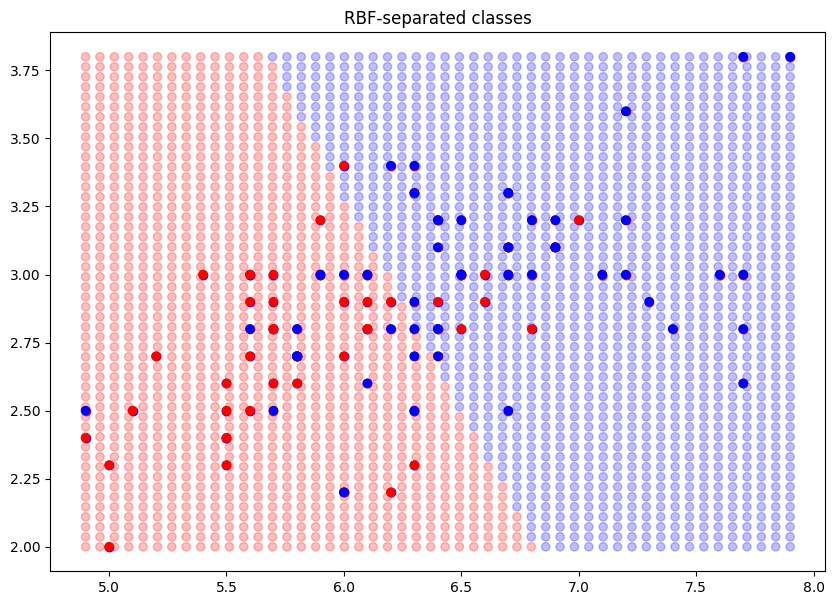

In [13]:
## 9. Visualize the RBF-SVM classification results.

from itertools import product

#Minima and maxima of both features
xmin, xmax = np.percentile(X[:, 0], [0, 100])
ymin, ymax = np.percentile(X[:, 1], [0, 100])

#Grid/Cartesian product with itertools.product
test_points = np.array([[xx, yy] for xx, yy in product(np.linspace(xmin, xmax), np.linspace(ymin, ymax))])

#Predictions on the grid
test_preds = grid_cv.predict(test_points)


X_1 = X[y == 1]
X_2 = X[y == 2]

%matplotlib inline
plt.figure(figsize=(10,7))   #change figure-size for easier viewing
plt.scatter(X_2[:,0],X_2[:,1], color = 'red')
plt.scatter(X_1[:,0],X_1[:,1], color = 'blue')

colors = np.array(['r', 'b'])
plt.scatter(test_points[:, 0], test_points[:, 1], color=colors[test_preds-1], alpha=0.25)
plt.scatter(X[:, 0], X[:, 1], color=colors[y-1])
plt.title("RBF-separated classes")
